# Necesidad de liquidez contingente: escenarios con IRL SFC

## Decisión y alcance
¿Cuánto activo líquido adicional sería necesario, bajo una regla hipotética, para alcanzar un colchón elegido sobre el requerimiento neto a 30 días? El ejercicio usa promedios mensuales reportados por entidades en Colombia. Es una **sensibilidad estática**; no estima una línea de crédito, probabilidad de incumplimiento ni tamaño de un fondo institucional.

Para cada entidad y corte: $\text{brecha}=\max(0,c\,RLN-ALM)$, con $c$ elegido por el analista. Comparamos 100 %, 120 % y 150 %. Agregar las brechas describe un total de fila bajo supuestos comunes, no una necesidad consolidada que reconozca transferencias o restricciones entre entidades.

## Resultado de este corte

En diciembre de 2022, una de 44 entidades reportantes quedó por debajo del objetivo hipotético de 120 % usando los importes publicados. La tensión conjunta de ALM −10 % y RLN +10 % elevó esa cifra a cinco y la suma descriptiva de brechas a 0,820 billones COP. Las cifras no miden acceso real a fondeo ni corresponden a posiciones actuales.

## Fuente, grano y supuestos
[SFC: companion IRL](../../../03-market-liquidity-research/03-liquidez-estocastica/observed-sfc-irl/README.md): 34 cortes mensuales, marzo 2020–diciembre 2022, entidades reportantes. ALM y RLN están en miles de COP; la razón observada puede diferir de la reconstrucción por redondeo. El indicador es promedio mensual, no una posición intradía. Los colchones de 120 % y 150 % son hipotéticos. Añadir ALM sin alterar RLN supone disponibilidad inmediata sin costo y no modela fondeo ni comportamiento de mercado.

[BCBS: principios de gestión de liquidez](https://www.bis.org/publ/bcbs144.htm) aportan contexto de planificación; esta aplicación no evalúa cumplimiento ni reproduce los cálculos prudenciales oficiales.

In [1]:
from pathlib import Path
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(9,4),'axes.grid':True,'grid.alpha':0.25})

In [2]:
p=root/'03-financial-risk/03-market-liquidity-research/03-liquidez-estocastica/observed-sfc-irl/results/sfc_irl_by_entity_month.csv'
print('SHA-256:',hashlib.sha256(p.read_bytes()).hexdigest()); df=pd.read_csv(p,parse_dates=['period'])
keys=['period','entity_code']; assert not df.duplicated(keys).any()
for c in ['alm_average_thousand_cop','rln_30d_average_thousand_cop']:
    df[c]=pd.to_numeric(df[c],errors='coerce')
print('Filas:',len(df),'| cortes:',df.period.nunique(),'| entidades:',df.entity_code.nunique(),'| periodo:',df.period.min().date(),df.period.max().date())
print('Faltantes:',df[keys+['alm_average_thousand_cop','rln_30d_average_thousand_cop']].isna().sum().to_dict())
assert df[keys+['alm_average_thousand_cop','rln_30d_average_thousand_cop']].notna().all().all()
assert (df.rln_30d_average_thousand_cop>0).all() and (df.alm_average_thousand_cop>=0).all()

SHA-256: d4b1e8eb6bb1606abd9c5f0fed572d00a19d2cd5a4da94d83eb4b5bb1c801929
Filas: 1438 | cortes: 34 | entidades: 48 | periodo: 2020-03-31 2022-12-31
Faltantes: {'period': 0, 'entity_code': 0, 'alm_average_thousand_cop': 0, 'rln_30d_average_thousand_cop': 0}


## Validación de unidades
Se contrasta la razón reconstruida a partir de los importes con el IRL publicado, sin modificar la fuente. Diferencias pequeñas pueden surgir de redondeos; no se sustituye la cifra oficial.

In [3]:
df['irl_reconstruido_pct']=100*df.alm_average_thousand_cop/df.rln_30d_average_thousand_cop
df['diferencia_pp']=df.irl_reconstruido_pct-df.irl_pct_reported
print('Diferencia absoluta mediana y máxima (pp):',df.diferencia_pp.abs().median(),df.diferencia_pp.abs().max())
df[['irl_pct_reported','irl_reconstruido_pct','diferencia_pp']].describe().round(3)

Diferencia absoluta mediana y máxima (pp): 4.133919162541133e-07 0.04995944662417173


,irl_pct_reported,irl_reconstruido_pct,diferencia_pp
count,1438.000,1438.000,1438.000
mean,404.282,404.282,-0.000
std,1345.539,1345.539,0.019
min,112.778,112.778,-0.050
25%,172.986,172.993,-0.000
50%,249.350,249.394,0.000
75%,438.614,438.601,0.000
max,47254.673,47254.673,0.050


## Tres umbrales de cobertura
Calculamos brecha por fila y proporción de entidades por corte. La brecha se expresa en **billones COP** (10¹² pesos): los importes originales están en miles de pesos y se dividen por 10⁹. La muestra puede cambiar de composición.

In [4]:
rows=[]
for target in [1.0,1.2,1.5]:
    x=df.copy(); x['brecha_miles_cop']=(target*x.rln_30d_average_thousand_cop-x.alm_average_thousand_cop).clip(lower=0)
    x['debajo']=x.brecha_miles_cop>0
    g=x.groupby('period').agg(n=('entity_code','size'),entidades_debajo=('debajo','sum'),brecha_miles_cop=('brecha_miles_cop','sum'))
    g['proporcion']=g.entidades_debajo/g.n;g['brecha_billones_cop']=g.brecha_miles_cop/1e9;g['objetivo']=target;rows.append(g.reset_index())
series=pd.concat(rows,ignore_index=True)
assert (series.entidades_debajo<=series.n).all()
series.sort_values('period').groupby('objetivo').tail(1)[['period','objetivo','n','entidades_debajo','proporcion','brecha_billones_cop']].round(3)

,period,objetivo,n,entidades_debajo,proporcion,brecha_billones_cop
67,2022-12-31,1.2,44,1,0.023,0.009
33,2022-12-31,1.0,44,0,0.000,0.000
101,2022-12-31,1.5,44,6,0.136,1.120


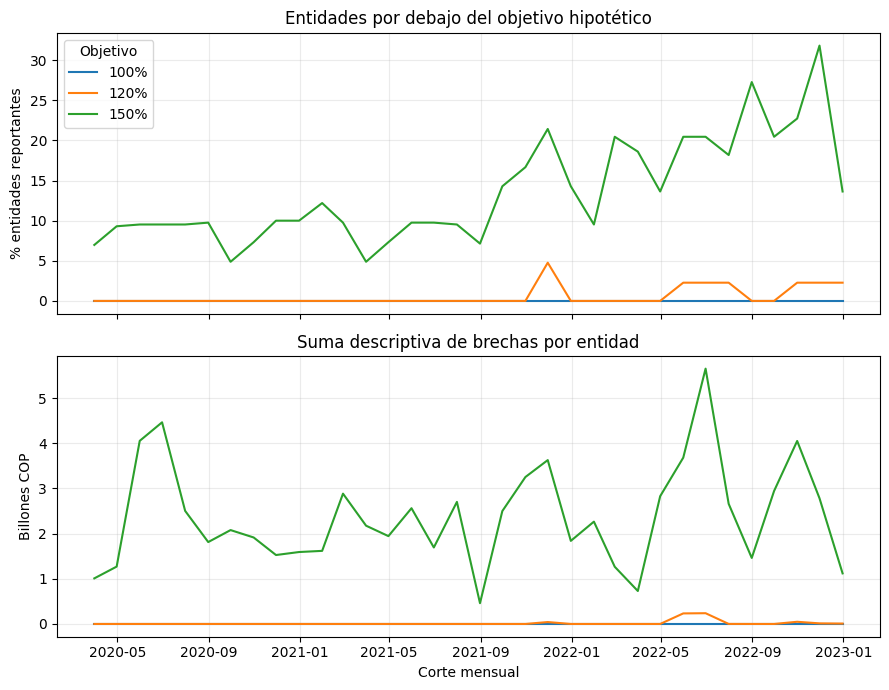

In [5]:
fig,axes=plt.subplots(2,1,figsize=(9,7),sharex=True)
for target,g in series.groupby('objetivo'):
    axes[0].plot(g.period,100*g.proporcion,label=f'{target:.0%}');axes[1].plot(g.period,g.brecha_billones_cop,label=f'{target:.0%}')
axes[0].set(title='Entidades por debajo del objetivo hipotético',ylabel='% entidades reportantes');axes[1].set(title='Suma descriptiva de brechas por entidad',ylabel='Billones COP',xlabel='Corte mensual');axes[0].legend(title='Objetivo');plt.tight_layout();plt.show()

## Sensibilidad de tensión simultánea
En el último corte aplicamos una reducción hipotética de 10 % a ALM y aumento de 10 % de RLN, sin compensaciones. La tensión es impuesta y no una frecuencia empírica. Se evalúa el objetivo de 120 % junto a la base.

In [6]:
last=df.loc[df.period.eq(df.period.max())].copy();target=1.2
base_gap=(target*last.rln_30d_average_thousand_cop-last.alm_average_thousand_cop).clip(lower=0)
stress_gap=(target*1.1*last.rln_30d_average_thousand_cop-.9*last.alm_average_thousand_cop).clip(lower=0)
assert (stress_gap>=base_gap).all()
pd.DataFrame({'escenario':['Base','ALM −10 %, RLN +10 %'],'entidades_con_brecha':[(base_gap>0).sum(),(stress_gap>0).sum()],'brecha_billones_COP':[base_gap.sum()/1e9,stress_gap.sum()/1e9]}).round(3)

,escenario,entidades_con_brecha,brecha_billones_COP
0,Base,1,0.009
1,"ALM −10 %, RLN +10 %",5,0.820


## Interpretación y límites
La aplicación sirve para explorar una regla y su sensibilidad a un corte histórico. No predice faltantes de caja ni indica si cada entidad podría cumplir el objetivo: requiere fuentes contractuales de fondeo, flujos diarios, costo, disponibilidad, colaterales, restricciones legales y un plan de contingencia aprobado. El cálculo no debe utilizarse como clasificación de solvencia.